In [12]:
# Import packages
import os
import glob
import json
import numpy as np
import netket as nk
import matplotlib.pyplot as plt
from scipy.sparse.linalg import eigsh

from DA_utils import build_system, get_TE_iters, load_TE_log

print("NetKet version:", nk.__version__)

NetKet version: 3.21.0


# **Load VMC Results**

In [13]:
# Load VMC results
VMC_dir = "Results/MixedIsing_L12_hx1.25_hz0.15_RBMSymm_alpha2_0914_1641"

with open(f"{VMC_dir}/VMC_metadata.json") as f:
  metadata = json.load(f)

# Rebuild system: 1D mixed-field Ising model
g, hi, ha, obs = build_system(metadata["system"])
corr_x_avg = obs["corr_x_avg"]
avg_mag_x = obs["avg_mag_x"]

In [14]:
# Compute energy eigenvalues
sp_ha = ha.to_sparse()
eig_vals, eig_vecs = eigsh(sp_ha, k=2, which="SA")
gs_state = eig_vecs[:, 0]

# Compute spectral gap
E_gs = eig_vals[0]
spectral_gap = eig_vals[1] - eig_vals[0]
print("Ground state energy: ", E_gs)
print("Spectral gap: ", spectral_gap)

# Compute exact ground state observables
corr_x_avg_gs = np.real(np.conjugate(gs_state) @ (corr_x_avg.to_sparse() @ gs_state))
avg_mag_x_gs = np.real(np.conjugate(gs_state) @ (avg_mag_x.to_sparse() @ gs_state))
conn_corr_x_avg_gs = corr_x_avg_gs - avg_mag_x_gs**2

print("Exact XX correlation function: " + str(corr_x_avg_gs))
print("Exact X magnetization: " + str(avg_mag_x_gs))
print("Exact XX connected correlation function: " + str(conn_corr_x_avg_gs))

Ground state energy:  -18.452612689696515
Spectral gap:  1.581015597793808
Exact XX correlation function: 0.5276978993790554
Exact X magnetization: 0.6549878937279061
Exact XX connected correlation function: 0.0986887584489366


In [15]:
# Standard VMC observables at every iteration from the VMC log
obs_names = ["corr_x_avg", "avg_mag_x"]

log = nk.utils.history.HistoryDict.from_file(f"{VMC_dir}/VMC_log.json")
O_vmc = {name: np.array(np.real(log[name].Mean)) for name in obs_names}
O_vmc_stdev = {name: np.array(np.real(log[name].Sigma)) for name in obs_names}

# Use the resampled observables (more samples) at the iterations where they exist
ns_resampled = 2**22
resampled_iters = []
for file in sorted(glob.glob(f"{VMC_dir}/VMC_log_resampled_*ns{ns_resampled}*.json")):
  res_log = nk.utils.history.HistoryDict.from_file(file)
  iters = np.array(res_log["Energy"].iters)
  for name in obs_names:
    O_vmc[name][iters] = np.real(res_log[name].Mean)
    O_vmc_stdev[name][iters] = np.real(res_log[name].Sigma)
  resampled_iters += iters.tolist()

print("Resampled iterations: ", sorted(resampled_iters))

Resampled iterations:  [149, 299, 449, 599, 749, 899, 1049, 1199, 1349, 1499, 1649, 1799, 1949, 2099, 2249, 2399, 2549, 2699, 2849, 2999]


# **Load Time Evolution**

In [16]:
# Time evolution (p-tVMC or TDVP) of the VMC states
TE_dirs = [
  f"{VMC_dir}/PTVMC_PPE2()_tf10.0_dt0.01_ns2048_ni20_20260915_031633",
]

# Resampled time evolution logs are used if they exist
dt_obs = 0.1
ns_TE_resampled = 2**21


def load_TE_observables(TE_dir, ITER):
  # Observables along the trajectory of VMC state ITER from the logs of the time evolution
  # t = 0 is the VMC state, t < 0 the backward and t > 0 the forward time evolution
  times_f, log_f = load_TE_log(TE_dir, ITER, "forward")
  times_b, log_b = load_TE_log(TE_dir, ITER, "backward")
  times = np.concatenate((-times_b[::-1], [0.0], times_f))

  O_t = {}
  O_t_stdev = {}
  for name in obs_names:
    O_t[name] = np.concatenate((np.real(log_b[name].Mean)[::-1], [O_vmc[name][ITER]], np.real(log_f[name].Mean)))
    O_t_stdev[name] = np.concatenate((np.real(log_b[name].Sigma)[::-1], [O_vmc_stdev[name][ITER]], np.real(log_f[name].Sigma)))

  # Error of the connected correlation function at every time
  O_t_stdev["conn_corr_x_avg"] = np.sqrt(O_t_stdev["corr_x_avg"]**2 + 4*O_t["avg_mag_x"]**2*O_t_stdev["avg_mag_x"]**2)

  return times, O_t, O_t_stdev


TE = {}
for TE_dir in TE_dirs:
  TE_file = f"{TE_dir}/TE_log_resampled_dt{dt_obs}_ns{ns_TE_resampled}.json"
  TE_resampled = json.load(open(TE_file))["results"] if os.path.exists(TE_file) else {}

  for ITER in get_TE_iters(TE_dir):
    if str(ITER) in TE_resampled:
      times = np.array(TE_resampled[str(ITER)]["times"])
      O_t = {name: np.array(O) for name, O in TE_resampled[str(ITER)]["series"].items()}
      O_t_stdev = {name: np.array(O) for name, O in TE_resampled[str(ITER)]["series_sigma"].items()}
      print(f"ITER = {ITER}: resampled time evolution log")
    else:
      times, O_t, O_t_stdev = load_TE_observables(TE_dir, ITER)
      print(f"ITER = {ITER}: time evolution log")
    TE[ITER] = (times, O_t, O_t_stdev)

ITER = 149: resampled time evolution log
ITER = 299: resampled time evolution log
ITER = 449: resampled time evolution log
ITER = 599: resampled time evolution log
ITER = 749: resampled time evolution log
ITER = 899: resampled time evolution log
ITER = 1049: resampled time evolution log
ITER = 1199: resampled time evolution log
ITER = 1349: resampled time evolution log
ITER = 1499: resampled time evolution log
ITER = 1649: resampled time evolution log
ITER = 1799: resampled time evolution log
ITER = 1949: resampled time evolution log
ITER = 2099: resampled time evolution log
ITER = 2249: resampled time evolution log
ITER = 2399: resampled time evolution log
ITER = 2549: resampled time evolution log
ITER = 2699: resampled time evolution log
ITER = 2849: resampled time evolution log
ITER = 2999: resampled time evolution log


# **Dynamical Averaging**

In [17]:
# Define functions used in dynamical averaging

def gaussian_weights(times, sigma):
  # Normalized Gaussian weights of width sigma centered at t = 0
  p = np.exp(-times**2/(2*sigma**2))
  return p/np.sum(p)




def dynamical_average(times, O_t, O_t_stdev, sigma):
  # Average an observable along a trajectory with Gaussian weights and propagate its error
  p = gaussian_weights(times, sigma)
  O_DA = np.sum(p*O_t)
  O_DA_stdev = np.sqrt(np.sum(p**2*O_t_stdev**2))
  return O_DA, O_DA_stdev




def dyn_avg_observables(times, O_t, O_t_stdev, sigma):
  # Compute the dynamically averaged observables of one VMC state from its trajectory
  O_DA = {}
  O_DA_stdev = {}
  for name in obs_names:
    O_DA[name], O_DA_stdev[name] = dynamical_average(times, O_t[name], O_t_stdev[name], sigma)

  # Connected correlation function of the dynamically averaged state
  p = gaussian_weights(times, sigma)
  O_DA["conn_corr_x_avg"] = O_DA["corr_x_avg"] - O_DA["avg_mag_x"]**2
  O_DA_stdev["conn_corr_x_avg"] = np.sqrt(np.sum(p**2*O_t_stdev["conn_corr_x_avg"]**2))

  return O_DA, O_DA_stdev

In [18]:
# Compute observables (standard and dynamically averaged) of the time evolved VMC states

# Widths of the Gaussian time window (e.g. sigma = 4/spectral_gap)
sigmas = [1.0, 3.0]

# Time evolved VMC iterations
iterations = np.array(sorted(TE.keys()))

# Standard observables
O_vs = {name: O_vmc[name][iterations] for name in obs_names}
O_vs_stdev = {name: O_vmc_stdev[name][iterations] for name in obs_names}

# Connected correlation function
O_vs["conn_corr_x_avg"] = O_vs["corr_x_avg"] - O_vs["avg_mag_x"]**2
O_vs_stdev["conn_corr_x_avg"] = np.sqrt(O_vs_stdev["corr_x_avg"]**2 + 4*O_vs["avg_mag_x"]**2*O_vs_stdev["avg_mag_x"]**2)

# Dynamically averaged observables for every sigma
O_vs_DA = {}
O_vs_DA_stdev = {}
for sigma in sigmas:
  O_vs_DA[sigma] = {name: np.zeros(len(iterations)) for name in O_vs}
  O_vs_DA_stdev[sigma] = {name: np.zeros(len(iterations)) for name in O_vs}

  for i, ITER in enumerate(iterations):
    times, O_t, O_t_stdev = TE[ITER]
    O_DA, O_DA_stdev = dyn_avg_observables(times, O_t, O_t_stdev, sigma)
    for name in O_DA:
      O_vs_DA[sigma][name][i] = O_DA[name]
      O_vs_DA_stdev[sigma][name][i] = O_DA_stdev[name]

In [19]:
# Define function to plot standard and dynamically averaged observables

def plot_observable(name, O_gs, ylabel):
  # Plot an observable and its relative error throughout optimization
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

  # --------------------------------
  # Observable
  # --------------------------------
  ax1.errorbar(
      iterations,
      O_vs[name],
      yerr=O_vs_stdev[name],
      fmt='o',
      linestyle='none',
      capsize=3,
      markersize=4,
      label="NQS"
  )

  for sigma in sigmas:
    ax1.errorbar(
        iterations,
        O_vs_DA[sigma][name],
        yerr=O_vs_DA_stdev[sigma][name],
        fmt='s',
        linestyle='none',
        capsize=3,
        markersize=4,
        label=rf"NQS + DA ($\sigma$ = {sigma})"
    )

  ax1.hlines(
      O_gs,
      xmin=iterations[0],
      xmax=iterations[-1],
      color="black",
      label="Exact Ground State"
  )

  ax1.set_xlabel("Iterations")
  ax1.set_ylabel(ylabel)
  ax1.legend()


  # --------------------------------
  # Relative error
  # --------------------------------
  ax2.errorbar(
      iterations,
      np.abs((O_vs[name] - O_gs) / O_gs),
      yerr=O_vs_stdev[name] / np.abs(O_gs),
      fmt='o',
      linestyle='none',
      capsize=3,
      markersize=4,
      label="NQS"
  )

  for sigma in sigmas:
    ax2.errorbar(
        iterations,
        np.abs((O_vs_DA[sigma][name] - O_gs) / O_gs),
        yerr=O_vs_DA_stdev[sigma][name] / np.abs(O_gs),
        fmt='s',
        linestyle='none',
        capsize=3,
        markersize=4,
        label=rf"NQS + DA ($\sigma$ = {sigma})"
    )

  ax2.set_yscale("log")
  ax2.set_xlabel("Iterations")
  ax2.set_ylabel("Relative Error")
  ax2.legend()

  plt.tight_layout()
  plt.show()

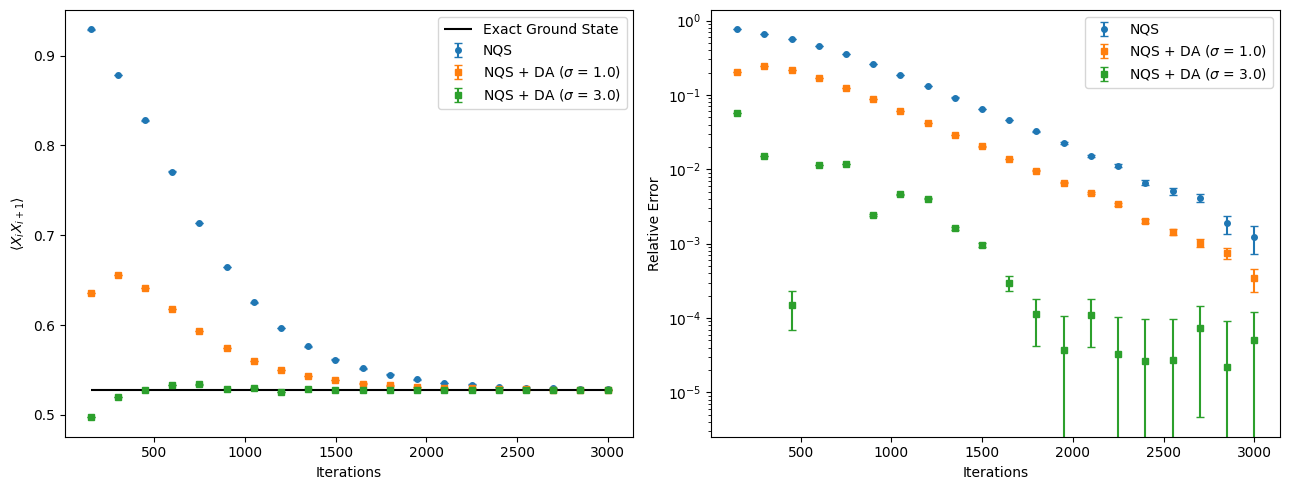

In [20]:
# Plot XX Correlation Function
plot_observable("corr_x_avg", corr_x_avg_gs, r"$\langle X_i X_{i+1} \rangle$")

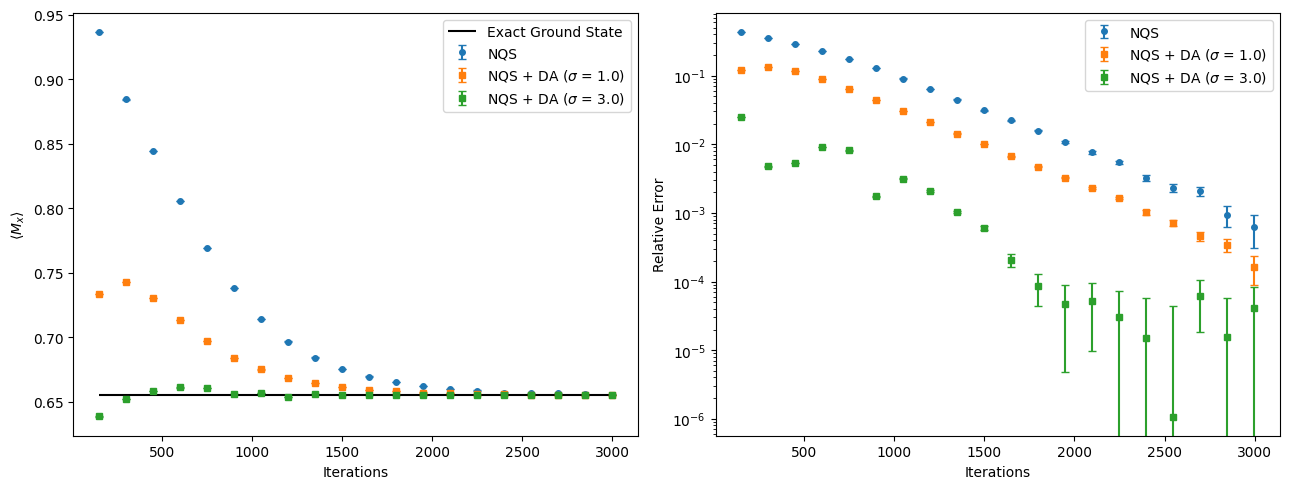

In [21]:
# Plot X Magnetization
plot_observable("avg_mag_x", avg_mag_x_gs, r"$\langle M_x \rangle$")

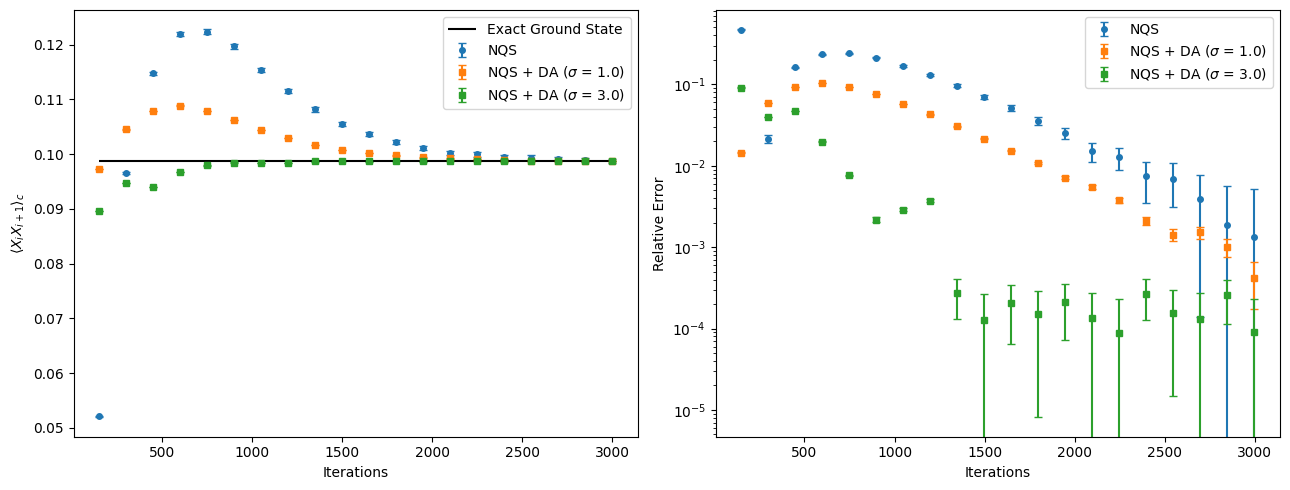

In [22]:
# Plot XX Connected Correlation Function
plot_observable("conn_corr_x_avg", conn_corr_x_avg_gs, r"$\langle X_i X_{i+1}\rangle_c$")